In [1]:
%load_ext autoreload
%autoreload 2

In [106]:
import numpy as np 
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from pathlib import Path
import os
from src.ekman import Ekman, EkmanConfig, Simulation, StateUpdater, rmse

from src.obsop import LinearObservationOperator


In [61]:
# --- Simulation Period
TTOT = 24 * 3600 # seconds

# --- True Parameters
UG_TRUE = 10    # m/s
K_TRUE = 2      # m^2/s

# --- Model error 
MODEL_ERROR = False
if MODEL_ERROR :
    UG_SIM = 9   # m/s
    K_SIM = 2.5     # m^2/s
else:
    UG_SIM = UG_TRUE
    K_SIM = K_TRUE

rng = np.random.default_rng(14)

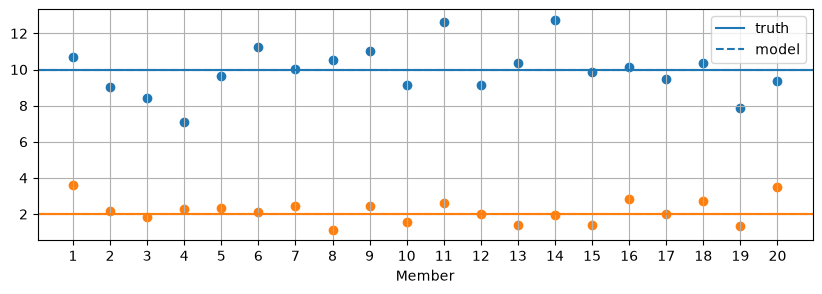

In [ ]:
# ======================
# --- Ensemble SetUp
# ======================

# Ens Size 
N = 20

# Ensemble uncertainties
sigma_ug = 1
sigma_lnK = 0.35

## Independent perturbations
# -- Additive random noise for geo-wind
ug_ens = UG_SIM + sigma_ug * rng.standard_normal(N)
vg_ens = np.zeros(N)
# -- Multiplicative log-normal noise for K
K_ens = K_SIM * np.exp(sigma_lnK * rng.standard_normal(N))


fig,ax=plt.subplots(figsize=(10,3))
ax.scatter(np.arange(1,21, dtype=int), ug_ens, color="tab:blue")
ax.axhline(y=UG_TRUE, color="tab:blue", label="truth")
ax.axhline(y=UG_SIM, color="tab:blue", linestyle="--", label="model")
ax.scatter(np.arange(1,21, dtype=int), K_ens, color="tab:orange")
ax.axhline(y=K_TRUE, color="tab:orange")
ax.axhline(y=K_SIM, color="tab:orange", linestyle="--")

ax.set_xlabel("Member")
ax.set_xticks([int(i) for i in range(1,21)])
ax.grid()
ax.legend()

In [67]:
# ====================
# --- TRUTH RUN
# ====================
SPINUP = 60 * 3600

config = EkmanConfig(spinup_seconds = SPINUP, output_interval = 60)
model_true = Ekman(ug=UG_TRUE, vg=0, K=K_TRUE, config=config)
model_true.spin_up()
sim_true = Simulation(model_true)
ds_true = sim_true.run(until=TTOT) # Control Forecast

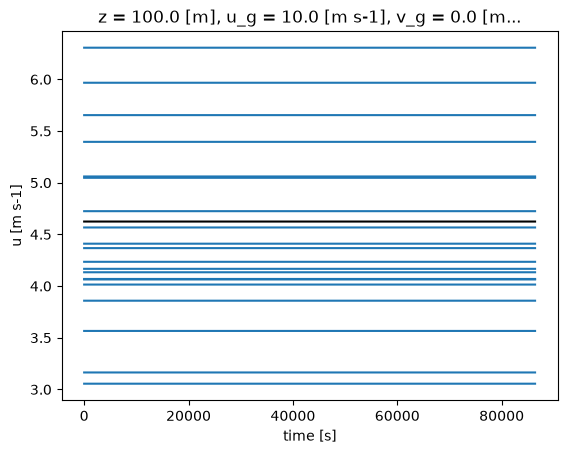

In [ ]:
# =========================
# --- Run Ensemble -- RAW
# =========================
ensraw = []
for i in range(N):
    u_memb, K_memb = ug_ens[i], K_ens[i]
    model_ens = Ekman(ug=u_memb, vg=0, K=K_memb, config=config)
    model_ens.spin_up()
    sim_ens = Simulation(model_ens)
    ds_memb = sim_ens.run(until=TTOT)
    ds_memb = ds_memb.expand_dims(ensemble=[i+1])
    ensraw.append(ds_memb)
ds_ens_raw = xr.concat(ensraw, dim="ensemble")

for i in range(N):
    ds_ens_raw.sel(ensemble=i+1, z=100)["u"].plot(c="tab:blue")
ds_true.sel(z=100)["u"].plot(c="k")


In [71]:

def assim_wind_seq(
    ug,
    K,
    vg: float =0,
    h_obs: int = 100,
    sigma_obs: float = 50,
    t0_assim: int = 3600,
    dt_assim: int = 7200,
    n_assim: int = 6,
    run_ctrl: bool = True
):


    print(f"SetUp Ekman with ug:{ug}, vg:{vg}, K:{K}")
    model = Ekman(ug=ug, vg=vg, K=K, config=config)
    model.spin_up()

    sim = Simulation(model)

    # --- Run DA-experiment
    analysis = sim.copy()
    # analysis_ds = analysis.run(until=3600)

    if run_ctrl:
        control = sim.copy()
        ds_ctrl = control.run(until=TTOT)


    # -- Schedule 6 assimilation updates
    for t in range(t0_assim, t0_assim+n_assim*dt_assim, dt_assim):

        # 1. Integrate to assimilation time
        analysis.run(until=t)

        # Get truth value
        utrue = ds_true.sel(time=t, z=H_OBS)["u"]
        vtrue = ds_true.sel(time=t, z=H_OBS)["v"]
        # Extract current background forecast
        idx = np.argmin(abs(analysis.model.z - H_OBS))
        ubg = analysis.model.state.u[idx]
        vbg = analysis.model.state.v[idx]
        # Calculate increments
        du = (utrue - ubg).item()
        dv = (vtrue - vbg).item()

        # Schedule assimilation
        analysis.schedule(t,StateUpdater(du=du, dv=dv, h_obs=h_obs, sigma=sigma_obs))

    # # --- Run simulation
    ds_analysis = analysis.run(until=TTOT)
    # analysis.schedule(1800, StateUpdater(du=1, dv=0.5, h_obs=100, sigma=25))
    # model.integrate(until=TTOT)
    # StateUpdater(du=1, dv=0.5, h_obs=100, sigma=25).update_step(model)


    if run_ctrl:
        return ds_analysis, ds_ctrl
    else:
        return ds_analysis


SetUp Ekman with ug:10.69551977003817, vg:0, K:3.618573188514523
SetUp Ekman with ug:9.020525831641269, vg:0, K:2.153536397750693
SetUp Ekman with ug:8.426509667052294, vg:0, K:1.8386060436029996
SetUp Ekman with ug:7.0750294281591355, vg:0, K:2.278852783096364
SetUp Ekman with ug:9.64676783641731, vg:0, K:2.3123389979002447
SetUp Ekman with ug:11.247606372611125, vg:0, K:2.1093573400409227
SetUp Ekman with ug:10.033072623469295, vg:0, K:2.4489342593735497
SetUp Ekman with ug:10.511844027680823, vg:0, K:1.1188353748224191
SetUp Ekman with ug:11.023238213663465, vg:0, K:2.459815946186168
SetUp Ekman with ug:9.117854151940106, vg:0, K:1.579980982287099
SetUp Ekman with ug:12.652286697169545, vg:0, K:2.63314277304232
SetUp Ekman with ug:9.12309174774362, vg:0, K:1.98518247433874
SetUp Ekman with ug:10.373553062187868, vg:0, K:1.4102728363647856
SetUp Ekman with ug:12.739580818116188, vg:0, K:1.9501403278506735
SetUp Ekman with ug:9.885747587848359, vg:0, K:1.4058879967590117
SetUp Ekman w

/var/folders/vl/cfpsjhj95nqglpsqx5nx9j040000gn/T/ipykernel_21396/4156640758.py:17: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  ds_ens_wind = xr.concat(enswind, dim="ensemble")


Text(0.5, 0.98, 'Ekman-Sim with ug: 10 & K: 2   ||   TRUTH ug:10 & K:2')

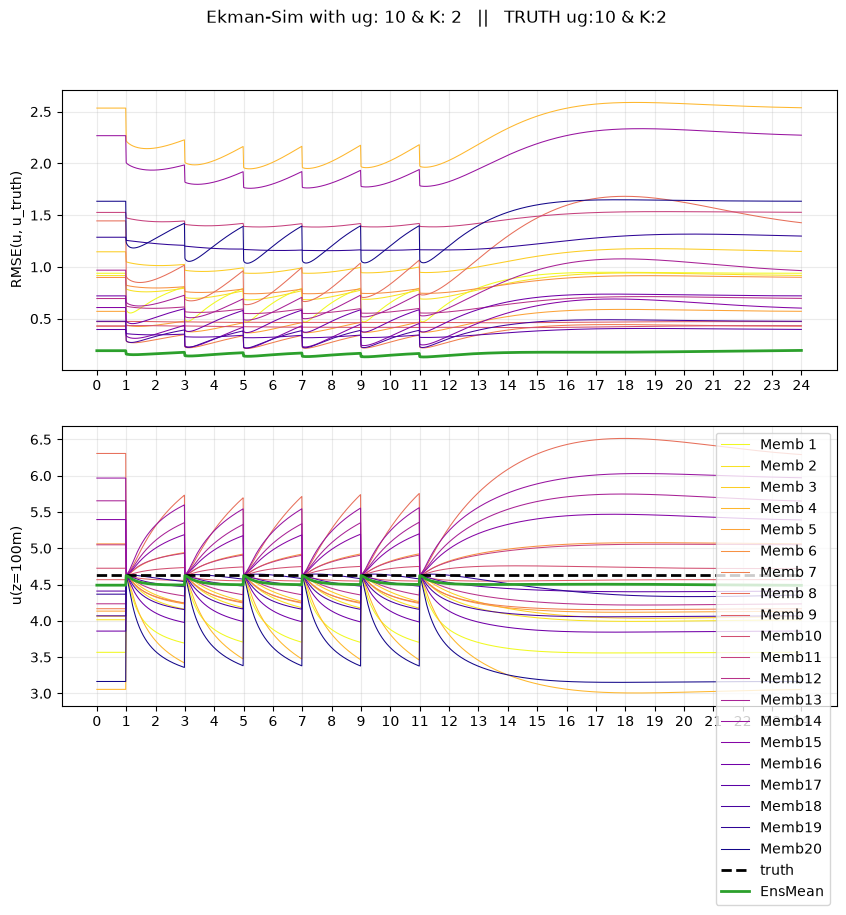

In [101]:
H_OBS=100
sigma_obs = 100

enswind = []

for i in range(N):
    u_memb, K_memb = ug_ens[i], K_ens[i]
    ds_ens = assim_wind_seq(
        u_memb, K_memb, 
        h_obs = H_OBS, 
        sigma_obs = sigma_obs,
        run_ctrl = False
        )
    ds_ens = ds_ens.expand_dims(ensemble=[i+1])
    enswind.append(ds_ens)

ds_ens_wind = xr.concat(enswind, dim="ensemble")


# ---- PLOTTING
fig, ax = plt.subplots(nrows=2, figsize=(10, 8))

H_PLOT = 100

# Colors from inferno colormap
cmap = plt.get_cmap("plasma_r")
colors = cmap(np.linspace(0, 0.99, len(ds_ens_wind.ensemble)))
for idx, color in enumerate(colors):

    ds_sim = ds_ens_wind.sel(ensemble=idx+1)
    label = f"Memb{idx+1:2d}"

    z = slice(None, None)
    rmse_da = rmse(ds_sim["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")
    # rmse_ctrl = rmse(ds_ctrl["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")

    ds_sim.u.sel(z=H_PLOT).plot(ax=ax[1], color=color, label=label, linewidth=0.75)
    rmse_da.plot(ax=ax[0], color=color, label=label, linewidth=0.75)

# rmse_ctrl.plot(ax=ax[0], c="k", linestyle="--", label="ctrl")

ds_true.u.sel(z=H_PLOT).plot(ax=ax[1], label="truth", c="k", linewidth=2, linestyle="--")
# ds_ctrl.u.sel(z=H_PLOT).plot(ax=ax[1], label="ctrl", c="k", linestyle="--")

# ------- ENS MEAn

ds_enswind_mean = ds_ens_wind.mean(dim="ensemble")
ds_enswind_mean.u.sel(z=H_PLOT).plot(ax=ax[1], color="tab:green", label="EnsMean", linewidth=2)
rmse_da = rmse(ds_enswind_mean["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")
rmse_da.plot(ax=ax[0], color="tab:green", label="EnsMean", linewidth=2)


ax[0].set_ylabel("RMSE(u, u_truth)")
ax[1].set_ylabel(f"u(z={H_PLOT}m)")

xticks = ds_sim.time.values[::60]
xlabels = [f'{int(x//3600)}' for x in xticks]
ax[1].set_xlabel("Time [h]")

for i in range(2):
    ax[i].set_xticks(xticks, labels=xlabels)
    ax[i].set_xlabel("")
    ax[i].grid(alpha=.25)
    ax[i].set_title("")

ax[1].legend(loc="upper right")
fig.suptitle(f"Ekman-Sim with ug: {UG_SIM} & K: {K_SIM}   ||   TRUTH ug:{UG_TRUE} & K:{K_TRUE}")

In [102]:


n = ds_ens_wind.sizes["ensemble"]
fig, axes = plt.subplots(4, 5, figsize=(15, 14), sharex=True, sharey=True)
colors = n*["tab:blue"] #plt.get_cmap("plasma_r")(np.linspace(0, 0.99, n))

lines = []
for j, ax in enumerate(axes.flat[:n]):
    truth, = ax.plot([], [], 'k-', lw=2.5, label="truth")
    ctrl,  = ax.plot([], [], 'k--', lw=2, label="control")
    assim, = ax.plot([], [], color=colors[j], lw=2, label="assimilation")
    lines.append((truth, ctrl, assim))
    ax.set_title(f"Member {ds_ens_wind.ensemble.values[j]}")
    ax.grid(alpha=0.25)

for ax in axes.flat[n:]:
    ax.set_visible(False)

datasets = [ds_true, ds_ens_raw, ds_ens_wind]
ax.set_xlim(min(float(ds.u.min()) for ds in datasets),
            max(float(ds.u.max()) for ds in datasets))
ax.set_ylim(float(ds_true.z.min()), float(ds_true.z.max()))

fig.supxlabel("u [m/s]")
fig.supylabel("z [m]")
fig.legend(*lines[0][0].axes.get_legend_handles_labels(),
           loc="upper center", ncol=3)
fig.tight_layout(rect=[0, 0, 1, 0.92])


def update(i):
    for j, (truth, ctrl, assim) in enumerate(lines):
        truth.set_data(ds_true.u.isel(time=i).values, ds_true.z.values)
        ctrl.set_data(ds_ens_raw.u.isel(time=i, ensemble=j).values, ds_ens_raw.z.values)
        assim.set_data(ds_ens_wind.u.isel(time=i, ensemble=j).values, ds_ens_wind.z.values)

    fig.suptitle(f"Time = {ds_true.time.values[i]/3600:.1f} h")
    return [line for panel in lines for line in panel]

ani = FuncAnimation(
    fig, update,
    frames=range(0, ds_ens_wind.sizes["time"], 30),
    interval=200,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())